# Congratulations, You Have a DAG. Now What?

**Authored by**: Camilo Saldarriaga, Alexander Fengler, Francesco Muia

**Monetary Policy Surprises and Equity Returns** (Bernanke & Kuttner 2005)

We take a well-known causal structure from the monetary-economics literature, instantiate it with three competing functional forms (linear, regime-switching, nonlinear), and use PyMC to recover the correct specification via LOO model comparison. Each functional form generates different results, and choosing the right one can be the edge that separates you from competitors trading the same insight.

In [1]:
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 12})
az.style.use("arviz-darkgrid")
%config InlineBackend.figure_format = "retina"

C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\site-packages\arviz\__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


## The DAG: Bernanke-Kuttner Channels

Two channels transmit monetary policy surprises to equity returns:

```
Macro news (MN) ──────────────────────────────────┐
               │                                  │
               ▼                                  ▼
  Monetary Policy surprise (MP_surp) ──────► Change in expected cash flows (ΔECF)  ──┐
               │              │                                                      │
               │              │                                                      ▼
               │              └────────────► Change in discount rates (ΔDR) ──► Equity return (R_eq)                             
               │                                  ▲                  ▲    ▲
               │                                  │                  │    │
               └──────────────────────────────────│──────────────────┘    │
                                                  │                       │
  Risk sentiment (RS) ────────────────────────────┴───────────────────────┘
```

| Variable | Symbol | Interpretation |
|----------|--------|----------------|
| Monetary policy surprise | MP_surp | Futures-implied surprise in target rate |
| Change in discount rates | ΔDR | Change in risk-free discounting / yields |
| Change in expected cash flows | ΔECF | Cash-flow news / expected earnings |
| Risk sentiment | RS | Time-varying risk appetite |
| Macro news | MN | Information moving both policy and cash flows |
| Equity returns | R_eq | Equity index return |

The structural model:

$$MP_{\text{surp}} = f_0(MN) + \varepsilon_0$$
$$\Delta DR = f_1(MP_{\text{surp}}, RS) + \varepsilon_1$$
$$\Delta ECF = f_2(MP_{\text{surp}}, MN) + \varepsilon_2$$
$$R_{eq} = f_3(\Delta DR, \Delta ECF, RS, MP_{\text{surp}}) + \varepsilon_3$$

The DAG is the same across all three specifications. The question is: **what are $f_0, f_1, f_2, f_3$?**

## Data Generating Process

We generate synthetic data from a regime-switching DGP that embeds sharp asymmetries between monetary-policy tightening and easing:

In [2]:
def dgp_mp_regime(n=2000, seed=42):
    rng = np.random.default_rng(seed)
    RS = rng.normal(0, 1, n)
    MN = rng.normal(0, 1, n)
    MP_surp = 0.5 * MN + 1.5 * rng.normal(0, 1, n)
    tightening = MP_surp > 0
    DR = (np.where(tightening, 1.8 * MP_surp, 0.3 * MP_surp)
          + 0.6 * RS + 0.7 * rng.normal(0, 1, n))
    ECF = (np.where(tightening, -0.2 * MP_surp, -1.0 * MP_surp)
           + 0.7 * MN + 0.7 * rng.normal(0, 1, n))
    Z = rng.normal(0, 1, n)           # independent contagion shock
    stress = Z > 1.0                  # ~16 % of observations
    R_eq = (
        -0.6 * DR + 0.8 * ECF + 0.5 * RS
        + np.where(stress, -5.0 * np.abs(MP_surp), 0.0)
        + 0.8 * rng.normal(0, 1, n)
    )
    return {"RS": RS, "MN": MN, "MP_surp": MP_surp,
            "DR": DR, "ECF": ECF, "R_eq": R_eq,
            "stress": stress.astype(float)}

In [3]:
N = 2000
data_true = dgp_mp_regime(n=N, seed=RANDOM_SEED)
df = pd.DataFrame(data_true)
df.describe().round(2)

,RS,MN,MP_surp,DR,ECF,R_eq,stress
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,-0.06,0.02,0.03,0.95,0.50,-1.25,0.16
std,1.00,1.00,1.61,2.09,1.28,3.63,0.37
min,-3.65,-3.06,-7.05,-3.20,-2.63,-23.95,0.00
25%,-0.72,-0.67,-1.03,-0.53,-0.39,-2.29,0.00
50%,-0.02,0.01,0.08,0.53,0.39,-0.63,0.00
75%,0.60,0.68,1.09,2.08,1.27,0.88,0.00
max,3.18,3.09,5.23,10.72,6.53,7.24,1.00


C:\Users\camil\AppData\Local\Temp\ipykernel_92656\2441735314.py:13: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


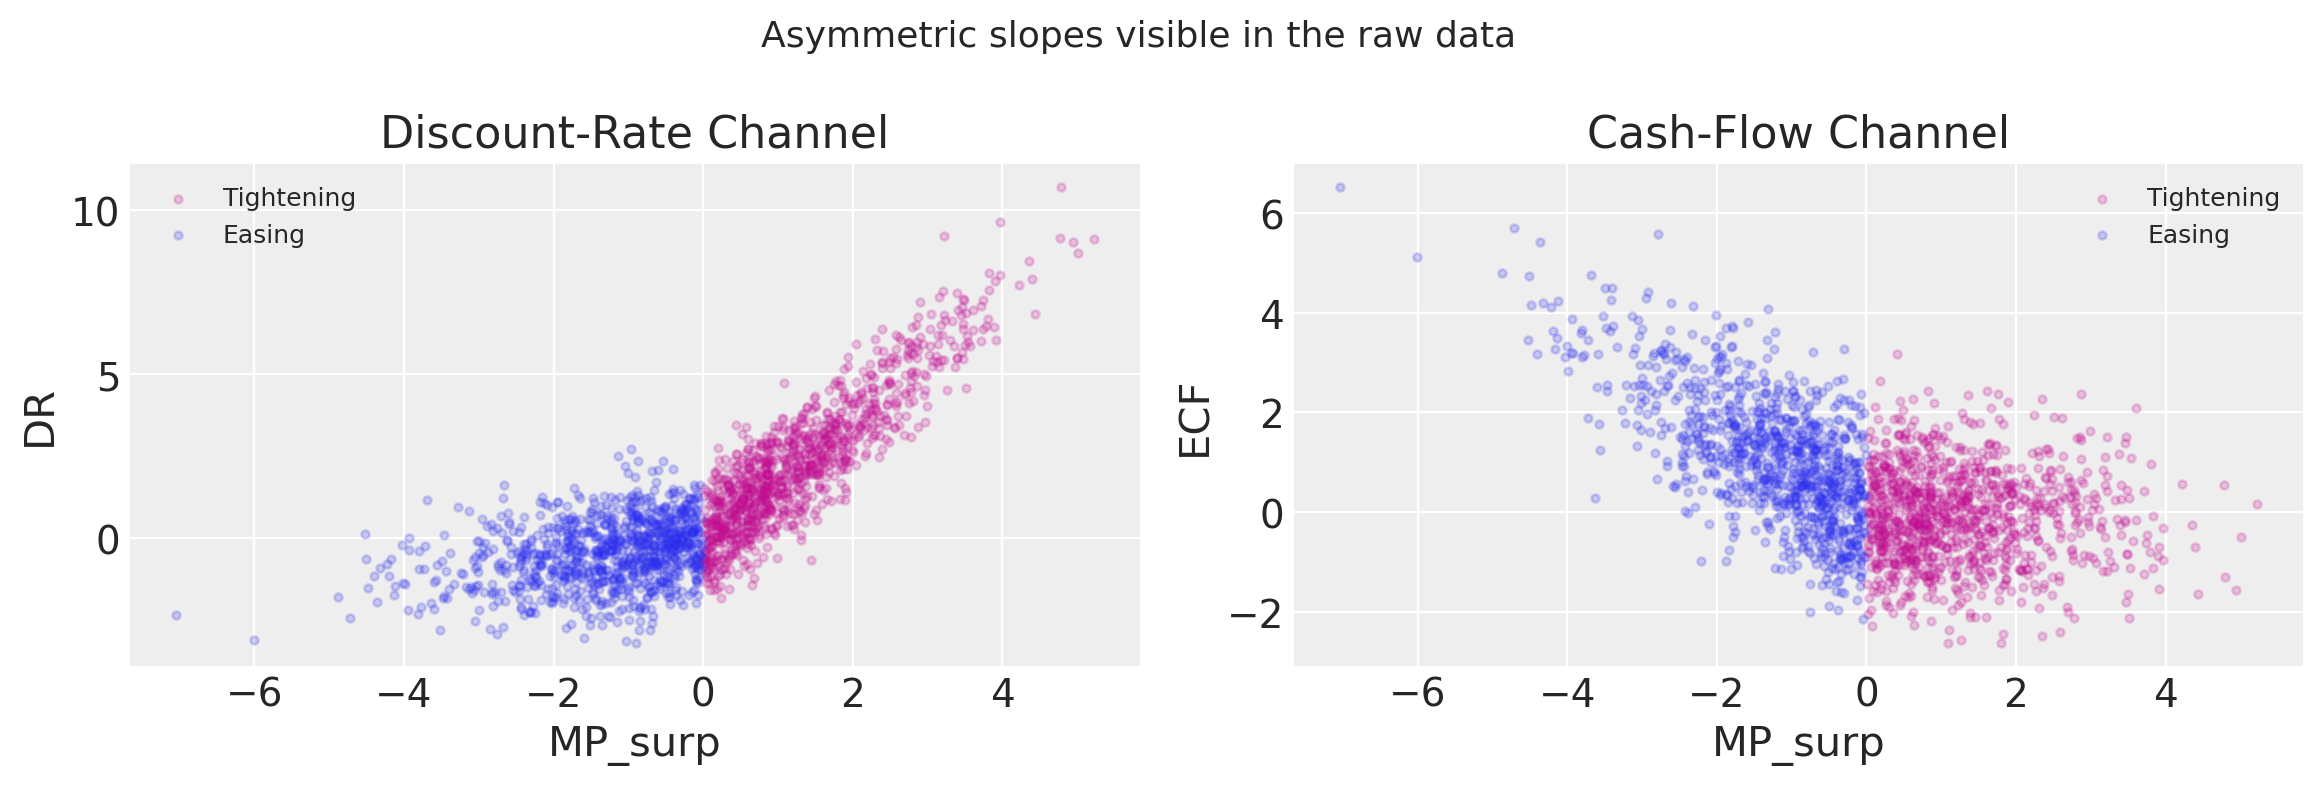

In [4]:
tightening = df["MP_surp"].values > 0

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, mask, color in [("Tightening", tightening, "C3"), ("Easing", ~tightening, "C0")]:
    axes[0].scatter(df["MP_surp"][mask], df["DR"][mask], alpha=0.2, s=8, label=label, color=color)
    axes[1].scatter(df["MP_surp"][mask], df["ECF"][mask], alpha=0.2, s=8, label=label, color=color)

axes[0].set(xlabel="MP_surp", ylabel="DR", title="Discount-Rate Channel")
axes[1].set(xlabel="MP_surp", ylabel="ECF", title="Cash-Flow Channel")
for ax in axes:
    ax.legend(fontsize=9)
fig.suptitle("Asymmetric slopes visible in the raw data", fontsize=13)
plt.tight_layout()

## PyMC Models

All three models encode the same DAG. They differ only in the functional forms of $f_1, f_2, f_3$.

In [5]:
# --- Model A: Linear ---
mp_vals = df["MP_surp"].values
rs_vals = df["RS"].values
mn_vals = df["MN"].values
dr_vals = df["DR"].values
ecf_vals = df["ECF"].values
req_vals = df["R_eq"].values

with pm.Model() as model_linear:
    # DR = a1*MP + a2*RS + noise
    a1 = pm.Normal("a1", mu=0, sigma=2)
    a2 = pm.Normal("a2", mu=0, sigma=2)
    sigma_dr = pm.HalfNormal("sigma_dr", sigma=2)
    pm.Normal("DR", mu=a1 * mp_vals + a2 * rs_vals, sigma=sigma_dr, observed=dr_vals)

    # ECF = b1*MP + b2*MN + noise
    b1 = pm.Normal("b1", mu=0, sigma=2)
    b2 = pm.Normal("b2", mu=0, sigma=2)
    sigma_ecf = pm.HalfNormal("sigma_ecf", sigma=2)
    pm.Normal("ECF", mu=b1 * mp_vals + b2 * mn_vals, sigma=sigma_ecf, observed=ecf_vals)

    # R_eq = c1*DR + c2*ECF + c3*RS + noise
    c1 = pm.Normal("c1", mu=0, sigma=2)
    c2 = pm.Normal("c2", mu=0, sigma=2)
    c3 = pm.Normal("c3", mu=0, sigma=2)
    sigma_req = pm.HalfNormal("sigma_req", sigma=2)
    pm.Normal("R_eq", mu=c1 * dr_vals + c2 * ecf_vals + c3 * rs_vals, sigma=sigma_req, observed=req_vals)

In [6]:
# --- Model B: Regime-switching ---
tight = (mp_vals > 0).astype(float)

with pm.Model() as model_regime:
    # Discount-rate change channel: separate slope per regime
    a1_t = pm.Normal("a1_tight", mu=0, sigma=2)
    a1_e = pm.Normal("a1_ease", mu=0, sigma=2)
    a2   = pm.Normal("a2", mu=0, sigma=2)
    dr_mu = (a1_t * tight + a1_e * (1 - tight)) * mp_vals + a2 * rs_vals
    pm.Normal("DR", mu=dr_mu, sigma=pm.HalfNormal("sigma_dr", 2), observed=dr_vals)

    # Cash-flow change channel: regime-dependent slopes
    b1_t = pm.Normal("b1_tight", mu=0, sigma=2)
    b1_e = pm.Normal("b1_ease", mu=0, sigma=2)
    b2   = pm.Normal("b2", mu=0, sigma=2)
    ecf_mu = (b1_t * tight + b1_e * (1 - tight)) * mp_vals + b2 * mn_vals
    pm.Normal("ECF", mu=ecf_mu, sigma=pm.HalfNormal("sigma_ecf", 2), observed=ecf_vals)

    # Equity returns: latent stress mixture
    c1 = pm.Normal("c1", mu=0, sigma=2)
    c2 = pm.Normal("c2", mu=0, sigma=2)
    c3 = pm.Normal("c3", mu=0, sigma=2)
    c_stress = pm.Normal("c_stress", mu=0, sigma=5)
    p_stress = pm.Beta("p_stress", alpha=2, beta=10)
    sigma_req = pm.HalfNormal("sigma_req", sigma=2)
    base_mu = c1*dr_vals + c2*ecf_vals + c3*rs_vals
    pm.Mixture(
        "R_eq",
        w=pt.stack([1 - p_stress, p_stress]),
        comp_dists=[
            pm.Normal.dist(mu=base_mu, sigma=sigma_req),
            pm.Normal.dist(mu=base_mu + c_stress * np.abs(mp_vals), sigma=sigma_req),
        ],
        observed=req_vals,
    )

In [7]:
# --- Model C: Nonlinear (tanh saturation + interaction) ---
with pm.Model() as model_nonlinear:
    # DR: tanh saturation + MP*RS interaction
    a1 = pm.Normal("a1", mu=0, sigma=2)
    a2 = pm.Normal("a2", mu=0, sigma=2)
    a3 = pm.Normal("a3", mu=0, sigma=2)
    a_s1 = pm.HalfNormal("a_scale1", sigma=2)
    a_s2 = pm.HalfNormal("a_scale2", sigma=2)
    sigma_dr = pm.HalfNormal("sigma_dr", sigma=2)
    dr_mu = a1 * pm.math.tanh(a_s1 * mp_vals) + a2 * pm.math.tanh(a_s2 * rs_vals) + a3 * mp_vals * rs_vals
    pm.Normal("DR", mu=dr_mu, sigma=sigma_dr, observed=dr_vals)

    # ECF: tanh saturation
    b1 = pm.Normal("b1", mu=0, sigma=2)
    b2 = pm.Normal("b2", mu=0, sigma=2)
    b_s1 = pm.HalfNormal("b_scale1", sigma=2)
    b_s2 = pm.HalfNormal("b_scale2", sigma=2)
    sigma_ecf = pm.HalfNormal("sigma_ecf", sigma=2)
    ecf_mu = b1 * pm.math.tanh(b_s1 * mp_vals) + b2 * pm.math.tanh(b_s2 * mn_vals)
    pm.Normal("ECF", mu=ecf_mu, sigma=sigma_ecf, observed=ecf_vals)

    # R_eq: linear combination
    c1 = pm.Normal("c1", mu=0, sigma=2)
    c2 = pm.Normal("c2", mu=0, sigma=2)
    c3 = pm.Normal("c3", mu=0, sigma=2)
    sigma_req = pm.HalfNormal("sigma_req", sigma=2)
    pm.Normal("R_eq", mu=c1 * dr_vals + c2 * ecf_vals + c3 * rs_vals, sigma=sigma_req, observed=req_vals)

## Sampling

In [ ]:
models = {"linear": model_linear, "regime": model_regime, "nonlinear": model_nonlinear}
traces = {}

for name, model in models.items():
    print(f"Sampling {name}...")
    with model:
        traces[name] = pm.sample(
            draws=500, tune=1000, chains=2,
            random_seed=RANDOM_SEED, target_accept=0.95,
        )
        pm.compute_log_likelihood(traces[name])

Sampling linear...


C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [a1, a2, sigma_dr, b1, b2, sigma_ecf, c1, c2, c3, sigma_req]


C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\
site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 1_000 tune and 500 draw iterations (2_000 + 1_000 draws total) took 10 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\
site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling regime...


... (3 outputs left out)

C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\
site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling nonlinear...


C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [a1, a2, a3, a_scale1, a_scale2, sigma_dr, b1, b2, b_scale1, b_scale2, sigma_ecf, c1, c2, c3, sigma_req]


C:\Users\camil\Documents\Servicios\PYMC-LABS\dags_adia_lab_workshop\congrats_you_have_a_dag\.pixi\envs\default\Lib\
site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

## Model Comparison (LOO)

In [ ]:
comparison = az.compare(traces, ic="loo", var_name="R_eq")
comparison

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3))
az.plot_compare(comparison, ax=ax, insample_dev=False)
ax.set_title("LOO Model Comparison: Same DAG, Three Functional Forms")
plt.tight_layout()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for i, (name, model) in enumerate(models.items()):
    with model:
        ppc = pm.sample_posterior_predictive(traces[name], random_seed=RANDOM_SEED)
    az.plot_ppc(ppc, var_names=["R_eq"], ax=axes[i], num_pp_samples=200, kind="cumulative")
    axes[i].set_title(f"{name}")
fig.suptitle("Posterior Predictive Checks: R_eq", fontsize=13)
plt.tight_layout()

## Right Form, Right DAG, Extra Edge

The LOO score is a statistical number. The return is the economic consequence.

A simple strategy: predict $R_{eq}$ from each model's posterior mean, go long if the prediction is positive, short if negative, and scale position by normalized confidence.

In [ ]:
def compute_strategy_pnl(trace, model, actual_req):
    with model:
        ppc = pm.sample_posterior_predictive(trace, random_seed=RANDOM_SEED)
    pred = ppc.posterior_predictive["R_eq"].mean(dim=["chain", "draw"]).values
    signal = np.sign(pred)
    size = np.clip(np.abs(pred) / np.std(pred), 0, 1)
    pnl = signal * size * actual_req
    return np.cumsum(pnl), pred

results = {}
for name, model in models.items():
    results[name] = compute_strategy_pnl(traces[name], model, req_vals)

In [ ]:
stress_mask = rs_vals > 1.0

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, (cum_pnl, _) in results.items():
    axes[0].plot(cum_pnl, label=name, alpha=0.9)
axes[0].set(xlabel="Event index", ylabel="Cumulative P&L", title="Cumulative P&L by Model")
axes[0].legend()
axes[0].axhline(0, color="black", ls="--", alpha=0.3)

colors = ["C0", "C1", "C2"]
for i, (name, (_, pred)) in enumerate(results.items()):
    signal = np.sign(pred)
    size = np.clip(np.abs(pred) / np.std(pred), 0, 1)
    pnl_stress = (signal * size * req_vals)[stress_mask].sum()
    axes[1].bar(name, pnl_stress, color=colors[i], alpha=0.8)
axes[1].set(title="Total P&L During Stress (RS > 1)", ylabel="Total P&L")

plt.tight_layout()

## The Pipeline

1. **Anchor on a candidate DAG** — from theory, literature, or a discovery algorithm. Know its assumptions.
2. **Propose competing functional forms** as PyMC models that all share the same graph.
3. **Fit and compare** with LOO. Let the data rule out misspecified structures.
4. **Check the tails** via posterior predictive checks — that is where misspecification hides.
5. **Test the economic consequence** — P&L simulation, hedging, risk attribution — because the edge from the right form is largest in the tails of the distribution.

Structure is the starting line, not the finish. A DAG without a functional form is a hypothesis without a prediction. PyMC gets you from graph to quantified, decision-ready structural model.